# Fase B — Limpieza y normalización de datos

**Proyecto 2 y 3 · Introducción a la Ciencia de los Datos · Hurto de motocicletas y automotores en Colombia**

**Dataset:** `Reporte_Hurto_por_Modalidades_Policía_Nacional_20260916.csv` (656.635 registros, enero 2010 a julio 2026)

**Pregunta de negocio:** ¿es posible predecir la cantidad de hurtos de motocicletas que se presentarán en un municipio durante el siguiente mes?

**Objetivo de esta fase:** dejar una tabla limpia, codificada y escalada, lista para modelar (Fase C), y guardarla en `datos_limpios.parquet`.


**Pasos:** 1) diagnóstico · 2) texto y fechas · 3) nulos · 4) tabla municipio-mes y atípicos · 5) transformación logarítmica · 6) rezagos y codificación · 7) escalado, partición y guardado.

## 1. Diagnóstico inicial

Revisamos dimensiones, tipos, nulos, duplicados y fechas antes de tocar nada.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

BASE = Path(r"C:\Users\Diego Gomez\OneDrive\Escritorio\ciencia de datos\Laboratorio_CienciaDatos")
RUTA = BASE / "datos" / "Reporte_Hurto_por_Modalidades_Policía_Nacional_20260916.csv"
SALIDA = BASE / "entrega"

df = pd.read_csv(RUTA)

print("Dimensiones:", df.shape)
print("\n--- Tipos y nulos ---")
print(pd.DataFrame({
    "dtype": df.dtypes,
    "nulos": df.isnull().sum(),
    "% nulos": (df.isnull().mean() * 100).round(3),
    "valores_unicos": df.nunique()
}))

print("\n--- Filas completamente duplicadas ---")
print("Duplicadas (excluye la primera aparición):", df.duplicated().sum())
print("Filas que pertenecen a algún grupo repetido:", df.duplicated(keep=False).sum())

print("\n--- Fechas: formato y rango ---")
fechas = pd.to_datetime(df["FECHA HECHO"], format="%d/%m/%Y", errors="coerce")
print("Fechas no convertibles:", fechas.isna().sum())
print("Rango:", fechas.min(), "->", fechas.max())

Dimensiones: (656635, 9)

--- Tipos y nulos ---
                dtype  nulos  % nulos  valores_unicos
DEPARTAMENTO   object      0    0.000              33
MUNICIPIO      object      0    0.000             976
CODIGO DANE     int64      0    0.000            2200
ARMAS MEDIOS   object      0    0.000              12
FECHA HECHO    object      0    0.000            6056
GENERO         object    712    0.108               3
GRUPO ETARIO   object    205    0.031               3
TIPO DE HURTO  object      0    0.000               2
CANTIDAD        int64      0    0.000               1

--- Filas completamente duplicadas ---
Duplicadas (excluye la primera aparición): 218780
Filas que pertenecen a algún grupo repetido: 313171

--- Fechas: formato y rango ---
Fechas no convertibles: 0
Rango: 2010-01-01 00:00:00 -> 2026-07-31 00:00:00



- Los únicos nulos están en `GENERO` (0,11 %) y `GRUPO ETARIO` (0,03 %), ambas categóricas.
- Hay 218.780 filas idénticas. Sin número de denuncia no se pueden distinguir de hechos distintos (por ejemplo, varias motos hurtadas el mismo día en el mismo municipio), así que **se conservan**, decisión ya tomada en la Fase A
- `CANTIDAD` vale siempre 1, no aporta información: la cantidad real se obtiene contando filas.
- Las fechas son todas válidas, entre 2010-01-01 y 2026-07-31.

## 2. Inconsistencias de texto y fechas

Revisamos las categorías, los espacios sobrantes y los municipios repetidos entre departamentos.

In [2]:
for col in ["DEPARTAMENTO", "ARMAS MEDIOS", "GENERO", "GRUPO ETARIO", "TIPO DE HURTO"]:
    print(f"\n=== {col} ===")
    print(df[col].value_counts(dropna=False).to_string())

print("\n--- Texto con espacios al inicio/final ---")
for col in ["DEPARTAMENTO", "MUNICIPIO", "ARMAS MEDIOS", "GENERO", "GRUPO ETARIO", "TIPO DE HURTO"]:
    s = df[col].dropna().astype(str)
    print(col, "->", (s != s.str.strip()).sum())

print("\n--- Municipios que se repiten en más de un departamento ---")
mun_dep = df.groupby("MUNICIPIO")["DEPARTAMENTO"].nunique()
print("Nombres en >1 departamento:", (mun_dep > 1).sum())
print(mun_dep[mun_dep > 1].head(10))

print("\nMunicipios con '(CT)':", df["MUNICIPIO"].str.contains(r"\(CT\)", na=False).sum())


=== DEPARTAMENTO ===
DEPARTAMENTO
ANTIOQUIA             144040
BOGOTA                113399
VALLE                 104537
CAUCA                  36692
ATLÁNTICO              33000
HUILA                  20806
NARIÑO                 19534
NORTE DE SANTANDER     18719
CESAR                  18497
SANTANDER              17530
CUNDINAMARCA           16199
META                   15733
GUAJIRA                13194
BOLÍVAR                12985
TOLIMA                  9875
MAGDALENA               9240
CÓRDOBA                 8358
CASANARE                6023
RISARALDA               5880
SUCRE                   5868
CHOCÓ                   5006
CAQUETÁ                 4651
PUTUMAYO                3415
QUINDÍO                 3275
ARAUCA                  2984
BOYACÁ                  2627
CALDAS                  2371
SAN ANDRÉS               814
GUAVIARE                 572
AMAZONAS                 437
VICHADA                  287
GUAINÍA                   49
VAUPÉS                    38

=== ARM


encontramos cuatro inconsistencias reales.
1. `GENERO` trae 60 registros `NO REPORTA`: es un nulo disfrazado de categoría, se convierte a `NaN`.
2. `ARMAS MEDIOS` tiene categorías solapadas (`CORTANTES`, `CORTOPUNZANTES`, `PUNZANTES`, `ARMAS BLANCAS`, `ARMA BLANCA / CORTOPUNZANTE`): todas son arma blanca y se agrupan.
3. `MUNICIPIO` lleva el sufijo `(CT)` en 429.316 filas. Es una marca de cabecera municipal, no parte del nombre: se separa en `ES_CAPITAL_CT`.
4. 58 nombres de municipio se repiten en varios departamentos, así que la llave del municipio es **departamento + municipio**.

No hay espacios sobrantes y los 33 departamentos son consistentes.

In [3]:
import unicodedata

df2 = df.copy()

# 1) Fecha y columnas derivadas
df2["FECHA"] = pd.to_datetime(df2["FECHA HECHO"], format="%d/%m/%Y")
df2["ANIO"] = df2["FECHA"].dt.year
df2["MES"] = df2["FECHA"].dt.month
df2["PERIODO"] = df2["FECHA"].dt.to_period("M")

# 2) Municipio: separar (CT) y limpiar el nombre
df2["ES_CAPITAL_CT"] = df2["MUNICIPIO"].str.contains(r"\(CT\)", na=False).astype(int)
df2["MUNICIPIO_LIMPIO"] = (df2["MUNICIPIO"]
                           .str.replace(r"\s*\(CT\)", "", regex=True)
                           .str.strip())

def sin_tildes(s):
    return "".join(c for c in unicodedata.normalize("NFD", s)
                   if unicodedata.category(c) != "Mn")

df2["LLAVE_MUN"] = (df2["DEPARTAMENTO"].str.upper().map(sin_tildes) + " | " +
                    df2["MUNICIPIO_LIMPIO"].str.upper().map(sin_tildes))

# 3) Tipo de vehículo
df2["TIPO_VEHICULO"] = df2["TIPO DE HURTO"].str.extract(r"HURTO (\w+)$")

# 4) Género: 'NO REPORTA' es un nulo disfrazado
df2["GENERO"] = df2["GENERO"].replace("NO REPORTA", np.nan)

# 5) Agrupar armas blancas
mapa_armas = {
    "ARMA BLANCA / CORTOPUNZANTE": "ARMA BLANCA",
    "CORTANTES": "ARMA BLANCA",
    "CORTOPUNZANTES": "ARMA BLANCA",
    "PUNZANTES": "ARMA BLANCA",
    "ARMAS BLANCAS": "ARMA BLANCA",
}
df2["ARMA_MEDIO"] = df2["ARMAS MEDIOS"].replace(mapa_armas)

# --- Verificaciones ---
print("Nulos GENERO tras convertir 'NO REPORTA':", df2["GENERO"].isna().sum())
print("\nARMA_MEDIO:")
print(df2["ARMA_MEDIO"].value_counts().to_string())

print("\nMunicipios únicos (nombre original):", df2["MUNICIPIO"].nunique())
print("Municipios únicos (nombre sin CT):  ", df2["MUNICIPIO_LIMPIO"].nunique())
print("Llaves únicas (departamento+municipio):", df2["LLAVE_MUN"].nunique())

mezcla = df2.groupby("LLAVE_MUN")["ES_CAPITAL_CT"].nunique()
print("Llaves con y sin (CT) a la vez:", (mezcla > 1).sum())

print("\nFilas por año:")
print(df2["ANIO"].value_counts().sort_index().to_string())

Nulos GENERO tras convertir 'NO REPORTA': 772

ARMA_MEDIO:
ARMA_MEDIO
LLAVE MAESTRA          225206
SIN EMPLEO DE ARMAS    193700
ARMA DE FUEGO          190560
ARMA BLANCA             16900
NO REPORTADO            14820
CONTUNDENTES            12289
ESCOPOLAMINA             3112
JERINGA                    48

Municipios únicos (nombre original): 976
Municipios únicos (nombre sin CT):   973
Llaves únicas (departamento+municipio): 1052
Llaves con y sin (CT) a la vez: 0

Filas por año:
ANIO
2010    21456
2011    30730
2012    31886
2013    32159
2014    31702
2015    35056
2016    39440
2017    41760
2018    42583
2019    46198
2020    36395
2021    44562
2022    49658
2023    53297
2024    51129
2025    44022
2026    24602



la llave departamento + municipio da 1.052 municipios, y ninguno aparece a veces con `(CT)` y a veces sin él. Las armas quedan en 8 categorías.

2010 tiene 21.456 filas frente a 30.730 de 2011: es el **subregistro** que ya detectó la Fase A (el registro salta +59 % entre diciembre de 2010 y enero de 2011). Por eso la serie de modelado arranca en **2011**.

## 3. Manejo de nulos (dos estrategias distintas)

| Columna | Nulos | Estrategia | Justificación |
|---|---|---|---|
| `GENERO` | 772 (0,12 %) | **Moda** (`MASCULINO`) | Es nominal y la categoría dominante pesa más del 80 %: imputar con la moda casi no altera la distribución. La media y la mediana no aplican a texto. |
| `GRUPO ETARIO` | 205 (0,03 %) | **Constante** `NO REPORTADO` | Conserva el hecho de que el dato faltaba. Igual se descarta como variable de modelado (99,3 % adultos). |

KNN no se usó: con tan pocos nulos y variables categóricas poco informativas no aporta nada frente a la moda.

In [4]:
print("ANTES")
print("GENERO nulos:", df2["GENERO"].isna().sum())
print("GRUPO ETARIO nulos:", df2["GRUPO ETARIO"].isna().sum())
print("\nDistribución de GENERO (sin nulos):")
print(df2["GENERO"].value_counts(normalize=True).round(4).to_string())

# Estrategia 1: moda para GENERO
moda_genero = df2["GENERO"].mode()[0]
print("\nModa de GENERO:", moda_genero)
df2["GENERO"] = df2["GENERO"].fillna(moda_genero)

# Estrategia 2: constante para GRUPO ETARIO
df2["GRUPO ETARIO"] = df2["GRUPO ETARIO"].fillna("NO REPORTADO")

print("\nDESPUÉS")
print("GENERO nulos:", df2["GENERO"].isna().sum())
print("GRUPO ETARIO nulos:", df2["GRUPO ETARIO"].isna().sum())
print("\nDistribución de GENERO tras imputar:")
print(df2["GENERO"].value_counts(normalize=True).round(4).to_string())
print("\nGRUPO ETARIO:")
print(df2["GRUPO ETARIO"].value_counts(normalize=True).round(4).to_string())

cols_uso = ["LLAVE_MUN", "DEPARTAMENTO", "ES_CAPITAL_CT", "ANIO", "MES",
            "TIPO_VEHICULO", "ARMA_MEDIO", "GENERO", "GRUPO ETARIO"]
print("\nNulos totales en columnas de uso:", df2[cols_uso].isna().sum().sum())

ANTES
GENERO nulos: 772
GRUPO ETARIO nulos: 205

Distribución de GENERO (sin nulos):
GENERO
MASCULINO    0.8081
FEMENINO     0.1919

Moda de GENERO: MASCULINO

DESPUÉS
GENERO nulos: 0
GRUPO ETARIO nulos: 0

Distribución de GENERO tras imputar:
GENERO
MASCULINO    0.8084
FEMENINO     0.1916

GRUPO ETARIO:
GRUPO ETARIO
ADULTOS         0.9932
ADOLESCENTES    0.0055
MENORES         0.0009
NO REPORTADO    0.0003

Nulos totales en columnas de uso: 0



la imputación casi no mueve la distribución de `GENERO` (80,81 % → 80,84 % masculino) y ya no quedan nulos en las columnas de uso.

## 4. Tabla municipio-mes y detección de atípicos

Como cada fila del archivo es un hurto, para predecir hay que **contar**. Construimos un panel con un registro por municipio y mes (solo municipios con al menos una moto hurtada, desde 2011), completando con 0 los meses sin hurtos. Después detectamos atípicos con IQR y Z-score.

In [5]:
# 1) Filtrar desde 2011 (2010 está subregistrado)
df3 = df2[df2["ANIO"] >= 2011].copy()
print("Filas desde 2011:", len(df3))

# 2) Conteos por municipio-mes
motos = df3[df3["TIPO_VEHICULO"] == "MOTOCICLETAS"]
autos = df3[df3["TIPO_VEHICULO"] == "AUTOMOTORES"]
cnt_motos = motos.groupby(["LLAVE_MUN", "PERIODO"]).size().rename("MOTOS")
cnt_autos = autos.groupby(["LLAVE_MUN", "PERIODO"]).size().rename("AUTOS")

# 3) Panel completo: municipios con al menos una moto x todos los meses
meses = pd.period_range("2011-01", "2026-07", freq="M")
munis = (motos[["LLAVE_MUN", "DEPARTAMENTO", "ES_CAPITAL_CT"]]
         .drop_duplicates("LLAVE_MUN"))

idx = pd.MultiIndex.from_product([munis["LLAVE_MUN"], meses],
                                 names=["LLAVE_MUN", "PERIODO"])
panel = pd.DataFrame(index=idx).reset_index()
panel = (panel
         .merge(munis, on="LLAVE_MUN", how="left")
         .merge(cnt_motos.reset_index(), on=["LLAVE_MUN", "PERIODO"], how="left")
         .merge(cnt_autos.reset_index(), on=["LLAVE_MUN", "PERIODO"], how="left"))

panel[["MOTOS", "AUTOS"]] = panel[["MOTOS", "AUTOS"]].fillna(0).astype(int)
panel["ANIO"] = panel["PERIODO"].dt.year
panel["MES"] = panel["PERIODO"].dt.month

print("\nMunicipios:", panel["LLAVE_MUN"].nunique())
print("Meses:", panel["PERIODO"].nunique())
print("Filas del panel:", len(panel), "(Fase A: 194.854)")
print("Total motos en el panel:", panel["MOTOS"].sum(), "| motos en df3:", len(motos))
print("% de municipio-meses con 0 motos:", round((panel["MOTOS"] == 0).mean() * 100, 1))
print("\nResumen de MOTOS:")
print(panel["MOTOS"].describe().round(2).to_string())

# 4) IQR a nivel municipio-mes
def iqr_limites(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1, q3, iqr, q1 - 1.5 * iqr, q3 + 1.5 * iqr

q1, q3, iqr, lo, hi = iqr_limites(panel["MOTOS"])
print(f"\n--- IQR municipio-mes ---\nQ1={q1}, Q3={q3}, IQR={iqr}, límite superior={hi}")
atip_mm = panel["MOTOS"] > hi
print("Atípicos municipio-mes:", atip_mm.sum(), f"({atip_mm.mean()*100:.1f} %)")

# 5) IQR a nivel municipio-año (como la Fase A)
anual = panel.groupby(["LLAVE_MUN", "ANIO"])["MOTOS"].sum().reset_index()
q1a, q3a, iqra, loa, hia = iqr_limites(anual["MOTOS"])
print(f"\n--- IQR municipio-año ---\nQ1={q1a}, Q3={q3a}, límite superior={hia}")
atip_a = anual["MOTOS"] > hia
print("Atípicos municipio-año:", atip_a.sum(), f"({atip_a.mean()*100:.1f} %)")

# 6) ¿Quiénes son los atípicos?
print("\nMunicipios con al menos un mes atípico:", panel[atip_mm]["LLAVE_MUN"].nunique())
print("Atípicos en capitales (CT):", round(panel[atip_mm]["ES_CAPITAL_CT"].mean() * 100, 1), "%")

# 7) Atípicos en el tiempo
print("\nMeses con menos motos a nivel nacional (desde 2011):")
nac = panel.groupby("PERIODO")["MOTOS"].sum()
print(nac.sort_values().head(5).to_string())

Filas desde 2011: 635179

Municipios: 1042
Meses: 187
Filas del panel: 194854 (Fase A: 194.854)
Total motos en el panel: 484382 | motos en df3: 484382
% de municipio-meses con 0 motos: 71.1

Resumen de MOTOS:
count    194854.00
mean          2.49
std          19.35
min           0.00
25%           0.00
50%           0.00
75%           1.00
max         658.00

--- IQR municipio-mes ---
Q1=0.0, Q3=1.0, IQR=1.0, límite superior=2.5
Atípicos municipio-mes: 22137 (11.4 %)

--- IQR municipio-año ---
Q1=0.0, Q3=8.0, límite superior=20.0
Atípicos municipio-año: 2240 (13.4 %)

Municipios con al menos un mes atípico: 594
Atípicos en capitales (CT): 21.6 %

Meses con menos motos a nivel nacional (desde 2011):
PERIODO
2020-04     855
2012-11    1336
2012-12    1439
2011-04    1551
2013-12    1562
Freq: M



decisión: se CONSERVAN todos los atípicos.
- El panel coincide con la Fase A: 194.854 filas, 1.042 municipios, 187 meses y 71,1 % de ceros. Las 484.382 motos del panel son las mismas de la fuente.
- **El IQR está degenerado:** con tantos ceros, Q1 = 0 y Q3 = 1, y el límite superior queda en 2,5. Marca como atípico a cualquier municipio-mes con 3 motos o más (11,4 %), o sea, a los municipios que no son pequeños, no a valores raros.
- Los atípicos están repartidos en cientos de municipios y solo el 21,6 % corresponde a capitales (CT): son conteos reales de municipios medianos y grandes.
- Los meses más bajos (abril de 2020, noviembre-diciembre de 2012) corresponden a la cuarentena y a un hueco de registro, es decir, eventos reales o limitaciones ya documentadas.
- Eliminarlos borraría justo a los municipios que más interesa predecir. La asimetría se trata con la transformación logarítmica, no con eliminación.

## 5. Transformación logarítmica

Comparamos tres cosas: Z-score como segundo detector de atípicos, `log(1+x)` y Yeo-Johnson para reducir la asimetría.

Atípicos por Z-score (|z|>3): 1062 (0.55 %)
Atípicos por IQR (límite 2.5): 22137 (11.4 %)

--- Asimetría (skewness) ---
MOTOS crudo:     18.56
MOTOS log(1+x):  2.8
AUTOS crudo:     24.05
AUTOS log(1+x):  5.78
MOTOS Yeo-Johnson: 1.01 | lambda: -1.886

Varianza/media de MOTOS: 150.7


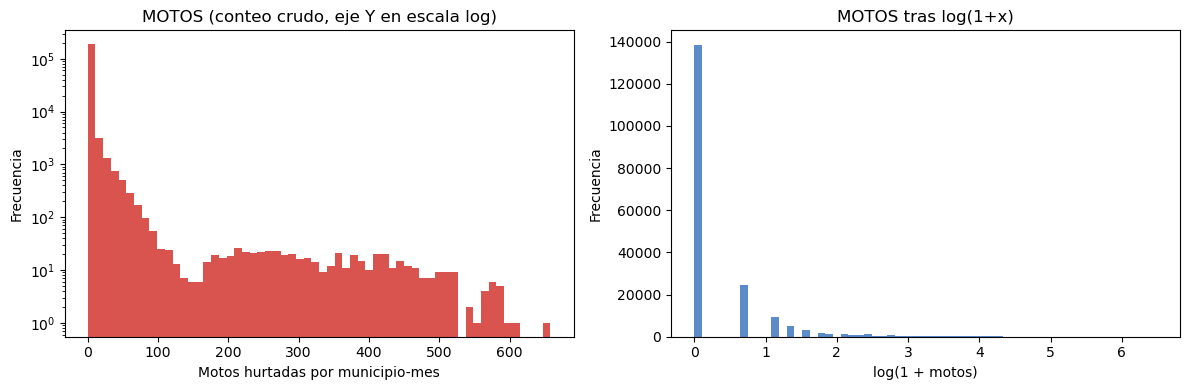

In [6]:
from scipy.stats import skew, kurtosis
from sklearn.preprocessing import PowerTransformer

# --- Z-score como segundo método de detección (sobre los conteos crudos) ---
z = (panel["MOTOS"] - panel["MOTOS"].mean()) / panel["MOTOS"].std()
print("Atípicos por Z-score (|z|>3):", (z.abs() > 3).sum(),
      f"({(z.abs() > 3).mean()*100:.2f} %)")
print("Atípicos por IQR (límite 2.5):", atip_mm.sum(), f"({atip_mm.mean()*100:.1f} %)")

# --- Sesgo antes y después ---
panel["MOTOS_LOG"] = np.log1p(panel["MOTOS"])
panel["AUTOS_LOG"] = np.log1p(panel["AUTOS"])

print("\n--- Asimetría (skewness) ---")
print("MOTOS crudo:    ", round(skew(panel["MOTOS"]), 2))
print("MOTOS log(1+x): ", round(skew(panel["MOTOS_LOG"]), 2))
print("AUTOS crudo:    ", round(skew(panel["AUTOS"]), 2))
print("AUTOS log(1+x): ", round(skew(panel["AUTOS_LOG"]), 2))

# --- Comparación con Yeo-Johnson ---
yj = PowerTransformer(method="yeo-johnson", standardize=False)
motos_yj = yj.fit_transform(panel[["MOTOS"]]).ravel()
print("MOTOS Yeo-Johnson:", round(skew(motos_yj), 2),
      "| lambda:", round(yj.lambdas_[0], 3))

# --- Varianza / media (sobredispersión) ---
print("\nVarianza/media de MOTOS:", round(panel["MOTOS"].var() / panel["MOTOS"].mean(), 1))

# --- Gráfico antes / después ---
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(panel["MOTOS"], bins=60, color="#d9534f")
ax[0].set_yscale("log")
ax[0].set_title("MOTOS (conteo crudo, eje Y en escala log)")
ax[0].set_xlabel("Motos hurtadas por municipio-mes"); ax[0].set_ylabel("Frecuencia")
ax[1].hist(panel["MOTOS_LOG"], bins=60, color="#5b8bc9")
ax[1].set_title("MOTOS tras log(1+x)")
ax[1].set_xlabel("log(1 + motos)"); ax[1].set_ylabel("Frecuencia")
plt.tight_layout(); plt.show()


- **Z-score vs IQR:** el Z-score marca solo 0,55 % (las grandes ciudades) y el IQR 11,4 %. Ninguno es confiable aquí: el Z-score asume una distribución casi normal y la varianza es unas 150 veces la media, y el IQR está degenerado por los ceros. Esto refuerza la decisión de conservar.
- **Sesgo:** la asimetría de `MOTOS` baja de 18,56 a 2,80 con `log(1+x)`. No baja más porque hay una masa enorme de ceros (unos 138.000 municipio-meses) que ninguna transformación puede quitar.
- **Por qué `log(1+x)` y no Yeo-Johnson:** Yeo-Johnson logra una asimetría de 1,01, pero con λ = −1,886 la transformación se satura (tiene un tope cercano a 0,53) y dejaría casi iguales a Medellín con 400 motos y a un municipio con 40. `log(1+x)` conserva las diferencias de magnitud, se revierte con `expm1` para reportar el error en motos reales y coincide con la Fase A.
- `AUTOS` queda más sesgada (5,78) porque tiene aún más ceros. Se usa solo como variable de apoyo (rezago), no como objetivo.

## 6. Variables de rezago y codificación de categóricas

**Rezagos** (decididos en la Fase A): mes anterior, promedio de los 3 meses previos, mismo mes del año anterior y autos del mes anterior. Todos usan **solo meses pasados** para no filtrar información del futuro. Como el rezago de 12 meses necesita un año de historia, 2011 queda como historia y las filas de modelado empiezan en enero de 2012.

**Codificación:**
- **One-Hot** (`drop_first=True`) para `DEPARTAMENTO` y `MES`: son nominales sin orden natural (con `MES` evitamos tratar diciembre como "mayor" que enero).
- **Ordinal** para `GRUPO ETARIO` (menores < adolescentes < adultos), el único con orden natural. Se muestra a nivel de fila, pero **no entra al modelo** por ser 99,3 % adultos.
- `ES_CAPITAL_CT` ya es binaria (0/1).

In [7]:
# 1) Variables de rezago (solo información pasada)
panel = panel.sort_values(["LLAVE_MUN", "PERIODO"]).reset_index(drop=True)
g = panel.groupby("LLAVE_MUN")

panel["MOTOS_LAG1"]  = g["MOTOS"].shift(1)
panel["MOTOS_PROM3"] = g["MOTOS"].transform(lambda s: s.shift(1).rolling(3).mean())
panel["MOTOS_LAG12"] = g["MOTOS"].shift(12)
panel["AUTOS_LAG1"]  = g["AUTOS"].shift(1)

# 2) Log(1+x) de los rezagos (misma escala que el objetivo)
for c in ["MOTOS_LAG1", "MOTOS_PROM3", "MOTOS_LAG12", "AUTOS_LAG1"]:
    panel[c + "_LOG"] = np.log1p(panel[c])

cols_lag = ["MOTOS_LAG1_LOG", "MOTOS_PROM3_LOG", "MOTOS_LAG12_LOG", "AUTOS_LAG1_LOG"]
print("Filas antes de quitar el primer año de historia:", len(panel))
modelo = panel.dropna(subset=cols_lag).copy()
print("Filas tras quitar 2011 (sin rezago de 12 meses):", len(modelo))
print("Periodo:", modelo["PERIODO"].min(), "->", modelo["PERIODO"].max())

# 3) Check de fuga: el promedio de 3 meses NO debe incluir el mes actual
ej = panel[panel["LLAVE_MUN"] == "ANTIOQUIA | MEDELLIN"].iloc[12:16][
    ["PERIODO", "MOTOS", "MOTOS_LAG1", "MOTOS_PROM3"]]
print("\nEjemplo Medellín (PROM3 debe usar solo los 3 meses anteriores):")
print(ej.to_string(index=False))

# 4) One-Hot (nominales) con drop_first=True
modelo_enc = pd.get_dummies(modelo, columns=["DEPARTAMENTO", "MES"],
                            drop_first=True, dtype=int)
print("\nColumnas nuevas por One-Hot:",
      len([c for c in modelo_enc.columns if c.startswith(("DEPARTAMENTO_", "MES_"))]))
print("Forma tras One-Hot:", modelo_enc.shape)

# 5) Ordinal: GRUPO ETARIO (único con orden natural), demostración a nivel de fila
orden_etario = {"MENORES": 0, "ADOLESCENTES": 1, "ADULTOS": 2}
df3["GRUPO_ETARIO_ORD"] = df3["GRUPO ETARIO"].map(orden_etario)
print("\nGRUPO ETARIO ordinal (NO REPORTADO queda NaN):")
print(df3["GRUPO_ETARIO_ORD"].value_counts(dropna=False).sort_index().to_string())

# 6) Nulos finales y asimetría de las variables numéricas
print("\nNulos en la tabla codificada:", modelo_enc.isna().sum().sum())
print("\nAsimetría de las variables numéricas:")
for c in ["MOTOS_LOG"] + cols_lag:
    print(f"{c}: {skew(modelo_enc[c]):.2f}")

Filas antes de quitar el primer año de historia: 194854
Filas tras quitar 2011 (sin rezago de 12 meses): 182350
Periodo: 2012-01 -> 2026-07

Ejemplo Medellín (PROM3 debe usar solo los 3 meses anteriores):
PERIODO  MOTOS  MOTOS_LAG1  MOTOS_PROM3
2012-01    408       413.0   447.666667
2012-02    579       408.0   448.666667
2012-03    554       579.0   466.666667
2012-04    521       554.0   513.666667

Columnas nuevas por One-Hot: 43
Forma tras One-Hot: (182350, 59)

GRUPO ETARIO ordinal (NO REPORTADO queda NaN):
GRUPO_ETARIO_ORD
0.0       600
1.0      3472
2.0    630929
NaN       178

Nulos en la tabla codificada: 0

Asimetría de las variables numéricas:
MOTOS_LOG: 2.74
MOTOS_LAG1_LOG: 2.74
MOTOS_PROM3_LOG: 2.88
MOTOS_LAG12_LOG: 2.81
AUTOS_LAG1_LOG: 5.72



- **Check de fuga superado:** en Medellín, el `MOTOS_LAG1` de febrero de 2012 (408) es el `MOTOS` de enero, y el `MOTOS_PROM3` de marzo es (413 + 408 + 579) / 3 ≈ 466,7. Cada rezago usa solo meses anteriores.
- Quedan 182.350 filas (enero 2012 a julio 2026) y 0 nulos. El One-Hot crea 43 columnas (32 de departamento y 11 de mes).
- El sesgo residual (2,7 a 2,9 en motos y 5,7 en autos) viene de la masa de ceros, no de un error del proceso.

## 7. Escalado, partición temporal y guardado

**Decisiones:**
- **Se escalan solo los 4 rezagos en log**, con **Z-score** (`StandardScaler`): ya están en la misma escala logarítmica y no tienen atípicos extremos. `RobustScaler` no conviene porque con tantos ceros su rango intercuartílico es casi degenerado. Min-Max se descartó por ser sensible a valores extremos.
- **No se escalan** las dummies ni `ES_CAPITAL_CT` (ya son 0/1).
- **No se escala el objetivo** `MOTOS_LOG`, para poder revertirlo directo con `expm1` y reportar el error en motos reales.
- **El escalador se ajusta solo con entrenamiento**, para que la media y la desviación no contengan información de los meses de prueba.
- **Partición temporal:** entrenamiento 2012-01 a 2024-12 y prueba 2025-01 a 2026-07. Este corte debe ser el mismo en la Fase C.

In [8]:
from sklearn.preprocessing import StandardScaler

# 1) Fecha en formato Timestamp (el parquet no maneja bien Period)
modelo_enc["FECHA_MES"] = modelo_enc["PERIODO"].dt.to_timestamp()

# 2) Partición temporal
corte = pd.Timestamp("2025-01-01")
es_train = modelo_enc["FECHA_MES"] < corte
modelo_enc["CONJUNTO"] = np.where(es_train, "train", "test")

print("Entrenamiento:", modelo_enc.loc[es_train, "FECHA_MES"].min().date(),
      "->", modelo_enc.loc[es_train, "FECHA_MES"].max().date(), "| filas:", es_train.sum())
print("Prueba:       ", modelo_enc.loc[~es_train, "FECHA_MES"].min().date(),
      "->", modelo_enc.loc[~es_train, "FECHA_MES"].max().date(), "| filas:", (~es_train).sum())

# 3) Z-score ajustado SOLO con entrenamiento
cols_esc = ["MOTOS_LAG1_LOG", "MOTOS_PROM3_LOG", "MOTOS_LAG12_LOG", "AUTOS_LAG1_LOG"]
scaler = StandardScaler().fit(modelo_enc.loc[es_train, cols_esc])

nuevas = [c.replace("_LOG", "_ESC") for c in cols_esc]
modelo_enc[nuevas] = scaler.transform(modelo_enc[cols_esc])

print("\nMedia y desviación aprendidas (solo train):")
print(pd.DataFrame({"media": scaler.mean_, "desv": scaler.scale_}, index=cols_esc).round(3))

print("\nVerificación: media/desv de las variables escaladas")
print("Train:\n", modelo_enc.loc[es_train, nuevas].agg(["mean", "std"]).round(3).to_string())
print("Test:\n", modelo_enc.loc[~es_train, nuevas].agg(["mean", "std"]).round(3).to_string())

# 4) Dataset final y guardado
final = modelo_enc.drop(columns=["PERIODO"])
print("\nForma final:", final.shape)
print("Nulos totales:", final.isna().sum().sum())

SALIDA.mkdir(exist_ok=True)
ruta_parquet = SALIDA / "datos_limpios.parquet"   # requiere pyarrow (pip install pyarrow)
final.to_parquet(ruta_parquet, index=False)

# 5) Verificar leyendo de nuevo
chk = pd.read_parquet(ruta_parquet)
print("\nParquet guardado en:", ruta_parquet.resolve())
print("Filas x columnas al releer:", chk.shape)
print("Peso (MB):", round(ruta_parquet.stat().st_size / 1e6, 2))
print("¿Igual al DataFrame final?", chk.shape == final.shape)
print("\nColumnas no dummies:")
print([c for c in chk.columns if not c.startswith(("DEPARTAMENTO_", "MES_"))])

Entrenamiento: 2012-01-01 -> 2024-12-01 | filas: 162552
Prueba:        2025-01-01 -> 2026-07-01 | filas: 19798

Media y desviación aprendidas (solo train):
                 media   desv
MOTOS_LAG1_LOG   0.407  0.811
MOTOS_PROM3_LOG  0.440  0.781
MOTOS_LAG12_LOG  0.389  0.798
AUTOS_LAG1_LOG   0.131  0.462

Verificación: media/desv de las variables escaladas
Train:
       MOTOS_LAG1_ESC  MOTOS_PROM3_ESC  MOTOS_LAG12_ESC  AUTOS_LAG1_ESC
mean             0.0             -0.0             -0.0             0.0
std              1.0              1.0              1.0             1.0
Test:
       MOTOS_LAG1_ESC  MOTOS_PROM3_ESC  MOTOS_LAG12_ESC  AUTOS_LAG1_ESC
mean           0.034            0.046            0.091           0.012
std            1.014            1.012            1.069           0.994

Forma final: (182350, 64)
Nulos totales: 0

Parquet guardado en: C:\Users\Diego Gomez\OneDrive\Escritorio\ciencia de datos\Laboratorio_CienciaDatos\entrega\datos_limpios.parquet
Filas x columnas al r


en entrenamiento las variables escaladas quedan con media 0 y desviación 1. En prueba la media sube un poco (0,03 a 0,09) porque el hurto crece con los años; no es una fuga de información, es el comportamiento esperado de una serie con tendencia.
